# Fase 3 - pipeline completo

Arma el score de habitabilidad desde `pois_detalle_por_proyecto.csv`, separa
los dos grupos, entrena baseline y autoencoder, compara metricas de
clasificacion y de contrafactuales DiCE entre ambas representaciones.

Archivos necesarios en la misma carpeta:

- `pois_detalle_por_proyecto.csv` (recoleccion, con nombre/tag/distancia por POI)
- `pois_ids_procesados.csv` (ids que ya se intentaron recolectar)
- `proyectos_geocodificados.xlsx` (coordenadas, distrito, precision_geocoding)
- `AvenidasLima.csv`, `LimaPobreza.csv`, `DenunciasLima.xlsx` (contexto)

Los proyectos que quedaron con 0 POIs en la recoleccion se descartan del
analisis (no se tratan como conteo 0, se sacan del dataset directamente).

In [105]:
%pip install dice-ml xgboost --quiet

try:
    import tensorflow as tf
    print('tensorflow ya disponible:', tf.__version__)
except ImportError:
    %pip install tensorflow --quiet
    import tensorflow as tf

tensorflow ya disponible: 2.20.0


In [106]:
import numpy as np, pandas as pd, unicodedata, warnings, os, time
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.base import BaseEstimator, ClassifierMixin
from tensorflow.keras import layers, Model, callbacks
import dice_ml
import matplotlib.pyplot as plt

# rutas
RUTA_DETALLE    = 'pois_detalle_por_proyecto.csv'
RUTA_IDS_OK     = 'pois_ids_procesados.csv'
RUTA_PROYECTOS  = 'proyectos_geocodificados.xlsx'
RUTA_AVENIDAS   = 'AvenidasLima.csv'
RUTA_POBREZA    = 'LimaPobreza.csv'
RUTA_DENUNCIAS  = 'DenunciasLima.xlsx'

THRESHOLD    = 0.60
RANDOM_STATE = 42
TEST_SIZE    = 0.20

# si el mejor modelo por F1 termina dando validity bajo en DiCE (nos paso con
# random forest), se puede forzar aca sin tener que rehacer todo el notebook
FORZAR_MODELO = None   # None = automatico por F1, o 'SVM' / 'XGBoost' / 'RandomForest'

DICE_METHOD           = 'random'
DICE_TOTAL_CFS        = 5
MAXITERATIONS_GENETIC = 50
MAX_PROYECTOS_DICE    = None   # limitar mientras se prueba, None para correr todos

POI_COLS = ['Bus','Primaria','Universitaria','Hospitales',
            'Alimentacion','Tienda','EspaciosPublicos','Farmacias']
POIS_MODIFICABLES = ['Bus','Primaria','Alimentacion','Tienda','EspaciosPublicos','Farmacias']

for p in [RUTA_DETALLE, RUTA_IDS_OK, RUTA_PROYECTOS, RUTA_AVENIDAS, RUTA_POBREZA, RUTA_DENUNCIAS]:
    print(('OK   ' if os.path.exists(p) else 'FALTA ') + p)

OK   pois_detalle_por_proyecto.csv
OK   pois_ids_procesados.csv
OK   proyectos_geocodificados.xlsx
OK   AvenidasLima.csv
OK   LimaPobreza.csv
OK   DenunciasLima.xlsx


## Utilidades

In [107]:
def norm_dist(s):
    if pd.isna(s): return s
    s = str(s).strip().upper()
    s = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    return ' '.join(s.split())

def fix_mojibake(s):
    if pd.isna(s): return s
    try:
        return str(s).encode('latin1').decode('utf-8')
    except (UnicodeDecodeError, UnicodeEncodeError):
        return s

## Conteos por proyecto, descartando los que salieron en 0

`pois_ids_procesados.csv` tiene todos los ids que se intentaron, incluidos los
que no encontraron ningun POI. Esos se sacan del dataset, no se dejan en 0.

In [108]:
ids_procesados = pd.read_csv(RUTA_IDS_OK)['id_proyecto'].tolist()
print(f'ids procesados en total: {len(ids_procesados)}')

detalle = pd.read_csv(RUTA_DETALLE)
print(f'filas en el detalle: {len(detalle)}')

ids_con_poi = set(detalle['id_proyecto'].unique())
ids_sin_poi = set(ids_procesados) - ids_con_poi
print(f'proyectos con al menos un POI: {len(ids_con_poi)}')
print(f'proyectos con 0 POIs (se descartan): {len(ids_sin_poi)}')

conteos = (detalle.groupby(['id_proyecto','categoria']).size()
                  .unstack('categoria', fill_value=0))
for c in POI_COLS:
    if c not in conteos.columns: conteos[c] = 0
conteos = conteos[POI_COLS].reset_index()

df = conteos.copy()
print(f'\nuniverso final (con poi, sin duplicar el filtro de 0): {len(df)}')

ids procesados en total: 1541
filas en el detalle: 105006
proyectos con al menos un POI: 1118
proyectos con 0 POIs (se descartan): 423

universo final (con poi, sin duplicar el filtro de 0): 1118


## Proyectos: direccion real, distrito, sin coordenadas repetidas

In [109]:
proyectos = pd.read_excel(RUTA_PROYECTOS)
proyectos = proyectos[proyectos['precision_geocoding'].isin(['direccion','calle'])].copy()
proyectos = proyectos.drop_duplicates(subset=['LATITUD','LONGITUD'], keep='first').reset_index(drop=True)
proyectos['Distrito_key'] = proyectos['DISTRITO'].astype(str).map(norm_dist)

df = df.merge(proyectos[['id_proyecto','DISTRITO','Distrito_key']], on='id_proyecto', how='inner')
print(f'universo final tras cruzar con proyectos geocodificados: {len(df)}')

universo final tras cruzar con proyectos geocodificados: 1118


## Score de habitabilidad

placeholder de la formula de fase 2, reemplazar si la version real es distinta

In [110]:
diccPeso = {"SALUD":0.25,"ALIMENTACION":0.22,"EDUCACION":0.20,
            "TRANSPORTE":0.15,"COMERCIO":0.10,"RECREACION":0.08}
diccRelevancia = {"Bus":1,"Primaria":2,"Universitaria":1,"Hospitales":3,
                  "Alimentacion":2,"Tienda":2,"EspaciosPublicos":3,"Farmacias":1}
diccSubCategorias = {'Bus':"TRANSPORTE",'Primaria':"EDUCACION",'Universitaria':"EDUCACION",
                     'Hospitales':"SALUD",'Farmacias':"SALUD",'Alimentacion':"ALIMENTACION",
                     'Tienda':"COMERCIO",'EspaciosPublicos':"RECREACION"}

def calcular_scoreH(frame, poi_cols=POI_COLS):
    counts = frame[poi_cols].astype(float).fillna(0)
    rel = pd.DataFrame({c: np.where(counts[c]>0, diccRelevancia.get(c,0), 0.0)
                        for c in poi_cols}, index=counts.index)
    scoreH = pd.Series(0.0, index=counts.index)
    for c in poi_cols:
        peso = diccPeso.get(diccSubCategorias.get(c), 0.0)
        scoreH += peso * rel[c] * np.log1p(counts[c])
    return scoreH

df['ScoreH'] = calcular_scoreH(df)
score_min, score_max = df['ScoreH'].min(), df['ScoreH'].max()
df['ScoreHNorm'] = (df['ScoreH']-score_min)/(score_max-score_min)
df['FlgHabita'] = (df['ScoreHNorm']>=THRESHOLD).astype(int)
print(df['FlgHabita'].value_counts())

FlgHabita
1    642
0    476
Name: count, dtype: int64


## Contexto: avenidas, pobreza, denuncias

In [111]:
aven = pd.read_csv(RUTA_AVENIDAS)
aven.columns = [c.strip() for c in aven.columns]
aven['id_proyecto'] = pd.to_numeric(aven['id_proyecto'], errors='coerce')
aven = aven.dropna(subset=['id_proyecto']).astype({'id_proyecto': int})
aven = aven[['id_proyecto','avenidas_unicas_5km','avenidas_unicas_10km']].drop_duplicates('id_proyecto')
df = df.merge(aven, on='id_proyecto', how='left')
print(f'con dato real de avenidas: {df["avenidas_unicas_5km"].notna().sum()} de {len(df)}')

pobreza = pd.read_csv(RUTA_POBREZA, encoding='latin1')
pobreza.columns = [c.strip().rstrip(';').strip() for c in pobreza.columns]
col_pobreza = 'Pobreza monetaria 2018'
pobreza['Distrito'] = pobreza['Distrito'].map(fix_mojibake).map(norm_dist)
pobreza = pobreza[['Distrito', col_pobreza]].dropna(subset=['Distrito']).drop_duplicates('Distrito')
df = df.merge(pobreza, left_on='Distrito_key', right_on='Distrito', how='left')
print(f'con dato real de pobreza: {df[col_pobreza].notna().sum()} de {len(df)}')

denuncias = pd.read_excel(RUTA_DENUNCIAS)
denuncias.columns = [c.strip() for c in denuncias.columns]
denuncias['DISTRITO'] = denuncias['DISTRITO'].map(norm_dist)
denuncias = denuncias[['DISTRITO','DENUNCIAS_2017']].dropna(subset=['DISTRITO']).drop_duplicates('DISTRITO')
df = df.merge(denuncias, left_on='Distrito_key', right_on='DISTRITO', how='left')
print(f'con dato real de denuncias: {df["DENUNCIAS_2017"].notna().sum()} de {len(df)}')
df = df.drop(columns=['Distrito','DISTRITO'], errors='ignore')

CONTEXT_COLS = ['avenidas_unicas_5km','avenidas_unicas_10km', col_pobreza, 'DENUNCIAS_2017']
for c in CONTEXT_COLS:
    df[c] = df[c].fillna(df[c].median())

con dato real de avenidas: 5 de 1118
con dato real de pobreza: 957 de 1118
con dato real de denuncias: 1050 de 1118


## Arrays de entrada y split

In [112]:
FEATURES_FULL = POI_COLS + CONTEXT_COLS
X_full = df[FEATURES_FULL].copy()
y = df['FlgHabita'].copy()

In [113]:
# split de 3 partes: train (para entrenar), validacion (para elegir el umbral), test (para reportar el resultado final, nunca tocado antes)
Xtr_full, Xtemp_full, ytr, ytemp = train_test_split(
    X_full, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)
Xval_full, Xte_full, yval, yte = train_test_split(
    Xtemp_full, ytemp, test_size=0.5, random_state=RANDOM_STATE, stratify=ytemp)

scaler_full = StandardScaler().fit(Xtr_full)
Xtr_full_s  = scaler_full.transform(Xtr_full)
Xval_full_s = scaler_full.transform(Xval_full)
Xte_full_s  = scaler_full.transform(Xte_full)

print(f'train: {len(Xtr_full)}  validacion: {len(Xval_full)}  test: {len(Xte_full)}')

train: 782  validacion: 168  test: 168


## Baseline: comparacion de modelos

In [114]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, precision_recall_curve

In [115]:
def encontrar_mejor_umbral(y_true, y_proba):
    precisiones, recalls, umbrales = precision_recall_curve(y_true, y_proba)
    f1s = 2 * (precisiones * recalls) / (precisiones + recalls + 1e-10)
    idx_mejor = np.argmax(f1s[:-1])
    return umbrales[idx_mejor], f1s[idx_mejor]

modelos_baseline = {
    'SVM':          SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE),
    'XGBoost':      XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', verbosity=0),
    'RandomForest': RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_estimators=300),
}

resultados_baseline = {}
umbrales_baseline = {}

for nombre, modelo in modelos_baseline.items():
    modelo.fit(Xtr_full_s, ytr)

    proba_val = modelo.predict_proba(Xval_full_s)[:, 1]
    umbral_opt, _ = encontrar_mejor_umbral(yval, proba_val)
    umbrales_baseline[nombre] = umbral_opt

    proba_test = modelo.predict_proba(Xte_full_s)[:, 1]
    pred_ajustado = (proba_test >= umbral_opt).astype(int)

    resultados_baseline[nombre] = {
        'Accuracy':  accuracy_score(yte, pred_ajustado),
        'Precision': precision_score(yte, pred_ajustado, zero_division=0),
        'Recall':    recall_score(yte, pred_ajustado, zero_division=0),
        'F1':        f1_score(yte, pred_ajustado, zero_division=0),
        'umbral':    round(umbral_opt, 3),
    }

tabla_baseline = pd.DataFrame(resultados_baseline).T.round(4)
print(tabla_baseline)

if FORZAR_MODELO:
    mejor_baseline_nombre = FORZAR_MODELO
else:
    mejor_baseline_nombre = tabla_baseline['F1'].idxmax()
svm_baseline = modelos_baseline[mejor_baseline_nombre]
umbral_baseline_elegido = umbrales_baseline[mejor_baseline_nombre]
print(f'modelo baseline elegido: {mejor_baseline_nombre}  (umbral: {umbral_baseline_elegido:.3f})')

              Accuracy  Precision  Recall      F1  umbral
SVM             0.9702     0.9596  0.9896  0.9744   0.476
XGBoost         0.9524     0.9783  0.9375  0.9574   0.672
RandomForest    0.9821     0.9895  0.9792  0.9843   0.513
modelo baseline elegido: RandomForest  (umbral: 0.513)


## Autoencoder

arquitectura con mas capacidad que un autoencoder minimo, mas early stopping
para no sobreajustar y darle una oportunidad real de superar al baseline

In [116]:
LATENT_DIM=8

In [117]:
#version1
"""
tf.random.set_seed(RANDOM_STATE)
INPUT_DIM = Xtr_full_s.shape[1]

inp = layers.Input(shape=(INPUT_DIM,))
h = layers.Dense(32, activation='relu')(inp)
h = layers.Dense(16, activation='relu')(h)
z = layers.Dense(LATENT_DIM, activation='linear', name='z')(h)
h2 = layers.Dense(16, activation='relu')(z)
h2 = layers.Dense(32, activation='relu')(h2)
out = layers.Dense(INPUT_DIM, activation='linear')(h2)

autoencoder = Model(inp, out)
encoder = Model(inp, z)
autoencoder.compile(optimizer='adam', loss='mse')

parada_temprana = callbacks.EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)
history = autoencoder.fit(Xtr_full_s, Xtr_full_s, validation_data=(Xval_full_s, Xval_full_s),
                           epochs=300, batch_size=32, callbacks=[parada_temprana], verbose=0)
print(f'epocas corridas: {len(history.history["loss"])}  |  loss val final: {history.history["val_loss"][-1]:.4f}')

Ztr = encoder.predict(Xtr_full_s, verbose=0)
Zte = encoder.predict(Xte_full_s, verbose=0)
Zval = encoder.predict(Xval_full_s, verbose=0)
"""

epocas corridas: 255  |  loss val final: 0.0376


In [130]:
tf.random.set_seed(RANDOM_STATE)
INPUT_DIM = Xtr_full_s.shape[1]

inp = layers.Input(shape=(INPUT_DIM,))
h = layers.Dense(32, activation='relu')(inp)
h = layers.Dense(16, activation='relu')(h)
z = layers.Dense(LATENT_DIM, activation='linear', name='z')(h)
h2 = layers.Dense(16, activation='relu')(z)
h2 = layers.Dense(32, activation='relu')(h2)
out = layers.Dense(INPUT_DIM, activation='linear')(h2)

autoencoder = Model(inp, out)
encoder = Model(inp, z)
autoencoder.compile(optimizer='adam', loss='mse')



# denoising: la entrada lleva ruido, pero el objetivo a reconstruir sigue siendo el original limpio
np.random.seed(RANDOM_STATE)
ruido = np.random.normal(0, 0.1, Xtr_full_s.shape)
Xtr_ruidoso = Xtr_full_s + ruido

parada_temprana = callbacks.EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)
history = autoencoder.fit(
    Xtr_ruidoso, Xtr_full_s,
    validation_data=(Xval_full_s, Xval_full_s),
    epochs=500, batch_size=32,
    callbacks=[parada_temprana], verbose=0
)
print(f'epocas corridas: {len(history.history["loss"])}  |  loss val final: {history.history["val_loss"][-1]:.4f}')

Ztr = encoder.predict(Xtr_full_s, verbose=0)
Zte = encoder.predict(Xte_full_s, verbose=0)
Zval = encoder.predict(Xval_full_s, verbose=0)

epocas corridas: 368  |  loss val final: 0.0338


In [132]:
from sklearn.model_selection import GridSearchCV

grillas = {
    'SVM': {
        'C': [0.1, 1, 10, 100, 1000],
        'gamma': ['scale', 0.01,0.05, 0.1, 0.5, 1],
    },
    'XGBoost': {
        'max_depth': [3, 5, 7, 9],
        'learning_rate': [0.01, 0.1, 0.3, 0.5],
        'n_estimators': [100, 300, 500],
    },
    'RandomForest': {
        'max_depth': [None, 10, 20],
        'min_samples_leaf': [1, 5, 10],
        'n_estimators': [200, 300, 500],
    },
}

def buscar_mejores_hiperparametros(X_train, y_train, nombre_modelo):
    base = {
        'SVM':          SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE),
        'XGBoost':      XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', verbosity=0),
        'RandomForest': RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    }[nombre_modelo]

    busqueda = GridSearchCV(base, grillas[nombre_modelo], scoring='f1', cv=5, n_jobs=-1)
    busqueda.fit(X_train, y_train)
    print(f'  {nombre_modelo}: mejores parametros = {busqueda.best_params_}  (F1 cv = {busqueda.best_score_:.4f})')
    return busqueda.best_estimator_

In [119]:
print('Buscando hiperparametros -- baseline:')
modelos_baseline = {
    nombre: buscar_mejores_hiperparametros(Xtr_full_s, ytr, nombre)
    for nombre in ['SVM', 'XGBoost', 'RandomForest']
}

Buscando hiperparametros -- baseline:
  SVM: mejores parametros = {'C': 1000, 'gamma': 0.01}  (F1 cv = 0.9722)
  XGBoost: mejores parametros = {'learning_rate': 0.5, 'max_depth': 7, 'n_estimators': 100}  (F1 cv = 0.9787)
  RandomForest: mejores parametros = {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}  (F1 cv = 0.9720)


In [133]:
print('Buscando hiperparametros -- autoencoder:')
modelos_ae = {
    nombre: buscar_mejores_hiperparametros(Ztr, ytr, nombre)
    for nombre in ['SVM', 'XGBoost', 'RandomForest']
}

resultados_ae = {}
umbrales_ae = {}

for nombre, modelo in modelos_ae.items():
    modelo.fit(Ztr, ytr)

    proba_val = modelo.predict_proba(Zval)[:, 1]
    umbral_opt, _ = encontrar_mejor_umbral(yval, proba_val)
    umbrales_ae[nombre] = umbral_opt

    proba_test = modelo.predict_proba(Zte)[:, 1]
    pred_ajustado = (proba_test >= umbral_opt).astype(int)

    resultados_ae[nombre] = {
        'Accuracy':  accuracy_score(yte, pred_ajustado),
        'Precision': precision_score(yte, pred_ajustado, zero_division=0),
        'Recall':    recall_score(yte, pred_ajustado, zero_division=0),
        'F1':        f1_score(yte, pred_ajustado, zero_division=0),
        'umbral':    round(umbral_opt, 3),
    }

tabla_ae = pd.DataFrame(resultados_ae).T.round(4)
print(tabla_ae)

if FORZAR_MODELO:
    mejor_ae_nombre = FORZAR_MODELO
else:
    mejor_ae_nombre = tabla_ae['F1'].idxmax()
svm_ae = modelos_ae[mejor_ae_nombre]
umbral_ae_elegido = umbrales_ae[mejor_ae_nombre]
print(f'modelo autoencoder elegido: {mejor_ae_nombre}  (umbral: {umbral_ae_elegido:.3f})')

comparacion = pd.DataFrame({
    f'baseline_{mejor_baseline_nombre}': tabla_baseline.loc[mejor_baseline_nombre],
    f'autoencoder_{mejor_ae_nombre}':    tabla_ae.loc[mejor_ae_nombre],
})
print()
print(comparacion)

Buscando hiperparametros -- autoencoder:
  SVM: mejores parametros = {'C': 10, 'gamma': 'scale'}  (F1 cv = 0.9607)
  XGBoost: mejores parametros = {'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 100}  (F1 cv = 0.9636)
  RandomForest: mejores parametros = {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}  (F1 cv = 0.9646)
              Accuracy  Precision  Recall      F1  umbral
SVM             0.9524     0.9314  0.9896  0.9596   0.372
XGBoost         0.9345     0.9570  0.9271  0.9418   0.585
RandomForest    0.9464     0.9780  0.9271  0.9519   0.647
modelo autoencoder elegido: SVM  (umbral: 0.372)

           baseline_RandomForest  autoencoder_SVM
Accuracy                  0.9821           0.9524
Precision                 0.9895           0.9314
Recall                    0.9792           0.9896
F1                        0.9843           0.9596
umbral                    0.5130           0.3720


In [155]:
tabla_baseline

,Accuracy,Precision,Recall,F1,umbral
SVM,0.9702,0.9596,0.9896,0.9744,0.476
XGBoost,0.9524,0.9783,0.9375,0.9574,0.672
RandomForest,0.9821,0.9895,0.9792,0.9843,0.513


## Wrappers para DiCE

In [134]:
class EncoderModelWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, scaler, encoder, clf, feature_order, umbral=0.5):
        self.scaler = scaler; self.encoder = encoder; self.clf = clf
        self.feature_order = feature_order; self.umbral = umbral
        self.classes_ = clf.classes_
    def _encode(self, X):
        X = X[self.feature_order].values if hasattr(X, 'columns') else X
        return self.encoder.predict(self.scaler.transform(X), verbose=0)
    def predict(self, X):
        proba = self.clf.predict_proba(self._encode(X))[:, 1]
        return (proba >= self.umbral).astype(int)
    def predict_proba(self, X):
        return self.clf.predict_proba(self._encode(X))

class BaselineModelWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, scaler, clf, feature_order, umbral=0.5):
        self.scaler = scaler; self.clf = clf
        self.feature_order = feature_order; self.umbral = umbral
        self.classes_ = clf.classes_
    def _scale(self, X):
        X = X[self.feature_order].values if hasattr(X, 'columns') else X
        return self.scaler.transform(X)
    def predict(self, X):
        proba = self.clf.predict_proba(self._scale(X))[:, 1]
        return (proba >= self.umbral).astype(int)
    def predict_proba(self, X):
        return self.clf.predict_proba(self._scale(X))

modelo_ae_wrapped   = EncoderModelWrapper(scaler_full, encoder, svm_ae, FEATURES_FULL, umbral=umbral_ae_elegido)
modelo_base_wrapped = BaselineModelWrapper(scaler_full, svm_baseline, FEATURES_FULL, umbral=umbral_baseline_elegido)

print('wrapper autoencoder ok:', (modelo_ae_wrapped.predict(Xte_full) == (modelos_ae[mejor_ae_nombre].predict_proba(Zte)[:,1] >= umbral_ae_elegido).astype(int)).mean())
print('wrapper baseline ok:', (modelo_base_wrapped.predict(Xte_full) == (modelos_baseline[mejor_baseline_nombre].predict_proba(Xte_full_s)[:,1] >= umbral_baseline_elegido).astype(int)).mean())

wrapper autoencoder ok: 1.0
wrapper baseline ok: 1.0


In [135]:
DICE_METHOD= 'random'

In [136]:
cost_dict = {'Bus':10,'Primaria':200,'Universitaria':300,'Hospitales':300,
             'Farmacias':40,'Tienda':30,'Alimentacion':20,'EspaciosPublicos':100}
constraints = {p: 15 for p in POIS_MODIFICABLES}

def build_dice_explainer(df_full, model, feature_cols, target_col='FlgHabita', method=DICE_METHOD):
    d2 = df_full[feature_cols].copy(); d2[target_col] = df_full[target_col].values
    data = dice_ml.Data(dataframe=d2, continuous_features=list(feature_cols), outcome_name=target_col)
    return dice_ml.Dice(data, dice_ml.Model(model=model, backend='sklearn'), method=method)

def run_dice(explainer, query, features_to_vary, total_CFs=DICE_TOTAL_CFS):
    orig = query.iloc[0]
    permitted = {p: [int(orig[p]), int(orig[p]) + constraints[p]] for p in features_to_vary}
    kwargs = {}
    if DICE_METHOD == 'genetic':
        kwargs['maxiterations'] = MAXITERATIONS_GENETIC
        kwargs['initialization'] = 'random'
    elif DICE_METHOD == 'random':
        kwargs['sample_size'] = 1000   # subido de 1000 -- mas intentos por llamada, mas chance de encontrar un punto valido
    return explainer.generate_counterfactuals(
        query, total_CFs=total_CFs, desired_class=1,
        features_to_vary=features_to_vary, permitted_range=permitted,
        posthoc_sparsity_param=0, **kwargs)

sn = df.loc[Xte_full.index, 'ScoreHNorm']
no_habitables_idx = sn[sn < THRESHOLD].index
proyectos_no_habitables = df.loc[no_habitables_idx, FEATURES_FULL + ['FlgHabita','ScoreHNorm','id_proyecto']].copy()
if MAX_PROYECTOS_DICE:
    proyectos_no_habitables = proyectos_no_habitables.head(MAX_PROYECTOS_DICE)
print(f'proyectos no habitables en test: {len(proyectos_no_habitables)}')

dice_explainer_ae   = build_dice_explainer(df, modelo_ae_wrapped, FEATURES_FULL)
dice_explainer_base = build_dice_explainer(df, modelo_base_wrapped, FEATURES_FULL)

proyectos no habitables en test: 72


In [137]:
def run_dice_con_reintentos(explainer, query, features_to_vary, total_CFs=DICE_TOTAL_CFS, intentos=2):
    ultimo_error = None
    for intento in range(intentos):
        try:
            return run_dice(explainer, query, features_to_vary, total_CFs=total_CFs)
        except Exception as e:
            ultimo_error = e
            continue
    raise ultimo_error

## Generacion de contrafactuales, con checkpoint

In [138]:
import os
if os.path.exists(RUTA_CHECKPOINT_DICE):
    os.remove(RUTA_CHECKPOINT_DICE)
    print('checkpoint borrado')

In [139]:
umbral_svm_baseline, _ = encontrar_mejor_umbral(yval, modelos_baseline['SVM'].predict_proba(Xval_full_s)[:, 1])
modelo_base_wrapped = BaselineModelWrapper(scaler_full, modelos_baseline['SVM'], FEATURES_FULL, umbral=umbral_svm_baseline)

print('modelo_base_wrapped ahora envuelve:', type(modelo_base_wrapped.clf).__name__)

modelo_base_wrapped ahora envuelve: SVC


In [140]:
dice_explainer_base = build_dice_explainer(df, modelo_base_wrapped, FEATURES_FULL)

In [141]:
RUTA_CHECKPOINT_DICE = 'per_home_checkpoint.csv'
GUARDAR_CADA_N_DICE = 5

if os.path.exists(RUTA_CHECKPOINT_DICE):
    per_home = pd.read_csv(RUTA_CHECKPOINT_DICE).to_dict('records')
    ya_hechos = {(r['id_proyecto'], r['metodo']) for r in per_home}
    print(f'checkpoint encontrado: {len(ya_hechos)} combinaciones ya procesadas')
else:
    per_home = []
    ya_hechos = set()

df_por_id = df.set_index('id_proyecto')
t0 = time.time()
proyectos_completados = 0

for i in range(len(proyectos_no_habitables)):
    try:
        pid = int(proyectos_no_habitables.iloc[i]['id_proyecto'])
    except (ValueError, TypeError) as e:
        print(f'proyecto en indice {i}: id_proyecto invalido ({e}), se omite')
        continue

    q = proyectos_no_habitables[FEATURES_FULL].iloc[[i]]
    score_antes = float(proyectos_no_habitables.iloc[i]['ScoreHNorm'])

    for nombre, expl in [('DiCE_baseline', dice_explainer_base), ('DiCE_autoencoder', dice_explainer_ae)]:
        if (pid, nombre) in ya_hechos:
            continue

        print(f'proyecto {i+1}/{len(proyectos_no_habitables)} (id {pid}) [{nombre}]: procesando...', flush=True)
        t_call = time.time()
        try:
            #otro dice
            cf = run_dice_con_reintentos(expl, q, POIS_MODIFICABLES, total_CFs=DICE_TOTAL_CFS, intentos=3)
            #cf = run_dice(expl, q, POIS_MODIFICABLES, total_CFs=DICE_TOTAL_CFS)
            cf_df = cf.cf_examples_list[0].final_cfs_df
            if cf_df is not None and len(cf_df):
                for cf_num, (_, best) in enumerate(cf_df.iterrows()):
                    fila_despues = q.iloc[0][POI_COLS].copy()
                    for p in POIS_MODIFICABLES:
                        fila_despues[p] = round(best[p])
                    scoreH_despues = calcular_scoreH(pd.DataFrame([fila_despues])).iloc[0]
                    score_despues = (scoreH_despues - score_min) / (score_max - score_min)

                    fila = {'metodo': nombre, 'id_proyecto': pid, 'cf_num': cf_num,
                            'score_antes': round(score_antes,4), 'score_despues': round(float(score_despues),4)}
                    for p in POI_COLS:
                        fila[f'{p}_existente'] = int(q.iloc[0][p])
                    for p in POIS_MODIFICABLES:
                        fila[f'+{p}'] = round(best[p]) - int(q.iloc[0][p])
                    per_home.append(fila)
                estado = f'ok ({len(cf_df)} CFs)'
            else:
                estado = 'sin contrafactual valido'
        except Exception as e:
            estado = f'error: {type(e).__name__}: {e}'

        print(f'  -> {estado}  ({time.time()-t_call:.1f}s, acumulado {(time.time()-t0)/60:.1f} min)', flush=True)

    proyectos_completados += 1
    if proyectos_completados % GUARDAR_CADA_N_DICE == 0:
        pd.DataFrame(per_home).to_csv(RUTA_CHECKPOINT_DICE, index=False)
        print(f'  checkpoint guardado ({len(per_home)} filas)')

pd.DataFrame(per_home).to_csv(RUTA_CHECKPOINT_DICE, index=False)
per_home = pd.DataFrame(per_home)
print(f'\ntotal de filas: {len(per_home)}  (tiempo total: {(time.time()-t0)/60:.1f} min)')

proyecto 1/72 (id 1916) [DiCE_baseline]: procesando...


100%|██████████| 1/1 [00:00<00:00, 11.64it/s]

  -> ok (5 CFs)  (0.1s, acumulado 0.0 min)
proyecto 1/72 (id 1916) [DiCE_autoencoder]: procesando...



100%|██████████| 1/1 [00:00<00:00,  1.90it/s]

  -> ok (5 CFs)  (0.6s, acumulado 0.0 min)
proyecto 2/72 (id 1674) [DiCE_baseline]: procesando...



100%|██████████| 1/1 [00:00<00:00, 10.09it/s]

... (371 outputs left out)


100%|██████████| 1/1 [00:00<00:00, 11.70it/s]

  -> ok (5 CFs)  (0.1s, acumulado 1.2 min)
proyecto 72/72 (id 202) [DiCE_autoencoder]: procesando...



100%|██████████| 1/1 [00:00<00:00,  1.52it/s]

  -> ok (5 CFs)  (0.7s, acumulado 1.2 min)

total de filas: 620  (tiempo total: 1.2 min)


## Metricas comparativas de contrafactuales

In [142]:
cols_delta = [f'+{p}' for p in POIS_MODIFICABLES]

per_home['sparsity'] = per_home[cols_delta].apply(lambda r: (r>0).sum(), axis=1)
per_home['proximity_L1'] = per_home[cols_delta].abs().sum(axis=1)
per_home['proximity_L2'] = np.sqrt((per_home[cols_delta]**2).sum(axis=1))
per_home['delta_score'] = per_home['score_despues'] - per_home['score_antes']
per_home['costo_total'] = sum(per_home[f'+{p}'] * cost_dict[p] for p in POIS_MODIFICABLES)

def calcular_validez(row):
    pid = row['id_proyecto']
    if pid not in df_por_id.index:
        return None
    original = df_por_id.loc[pid, FEATURES_FULL].copy()
    fila = original.copy()
    for p in POIS_MODIFICABLES:
        fila[p] = original[p] + row[f'+{p}']
    fila_df = pd.DataFrame([fila])[FEATURES_FULL]
    modelo = modelo_base_wrapped if row['metodo'] == 'DiCE_baseline' else modelo_ae_wrapped
    return int(modelo.predict(fila_df)[0]) == 1

per_home['valido'] = per_home.apply(calcular_validez, axis=1)

metricas = per_home.groupby('metodo').agg(
    validity           = ('valido', 'mean'),
    sparsity_prom      = ('sparsity', 'mean'),
    proximity_L1_prom  = ('proximity_L1', 'mean'),
    proximity_L2_prom  = ('proximity_L2', 'mean'),
    delta_score_prom   = ('delta_score', 'mean'),
    costo_prom         = ('costo_total', 'mean'),
).round(3)
print(metricas)
metricas.to_csv('metricas_comparativas_dice.csv')

                  validity  sparsity_prom  proximity_L1_prom  \
metodo                                                         
DiCE_autoencoder     1.000          2.486             27.853   
DiCE_baseline        0.908          2.854             32.400   

                  proximity_L2_prom  delta_score_prom  costo_prom  
metodo                                                             
DiCE_autoencoder             17.971             0.111    1489.000  
DiCE_baseline                19.242             0.111    2040.192  


## Ordenar por costo

In [147]:
per_home_ordenado = per_home.sort_values('costo_total').reset_index(drop=True)
per_home_ordenado.to_csv('contrafactuales_ordenados_por_costo.csv', index=False)

mas_barato_por_proyecto = (per_home.sort_values('costo_total')
                                    .groupby(['id_proyecto','metodo'])
                                    .first()
                                    .reset_index())
mas_barato_por_proyecto.to_csv('contrafactual_mas_barato_por_proyecto.csv', index=False)
print(f'contrafactual mas barato por proyecto+metodo: {len(mas_barato_por_proyecto)} filas')

contrafactual mas barato por proyecto+metodo: 130 filas


## Exportar dataset y modelos

In [146]:
import joblib
autoencoder.save('autoencoder_pois_contexto.keras')
joblib.dump({
    'modelo_baseline': svm_baseline, 'nombre_baseline': mejor_baseline_nombre,
    'modelo_ae': svm_ae, 'nombre_ae': mejor_ae_nombre,
    'scaler_full': scaler_full, 'features_full': FEATURES_FULL,
    'pois_modificables': POIS_MODIFICABLES, 'constraints': constraints, 'cost_dict': cost_dict,
    'threshold': THRESHOLD, 'score_min': score_min, 'score_max': score_max,
}, 'modelo_fase3_final.joblib')

df.to_csv('dataset_fase3_final.csv', index=False, encoding='utf-8-sig')
tabla_baseline.to_csv('comparacion_modelos_baseline.csv', encoding='utf-8-sig')
tabla_ae.to_csv('comparacion_modelos_autoencoder.csv', encoding='utf-8-sig')
print('exportado')

exportado


## Mini-EDA: categorias mas recomendadas por metodo

In [143]:
cols = [f'+{p}' for p in POIS_MODIFICABLES]

if per_home.empty:
    print('per_home vacio, sin datos para el resumen')
else:
    resumen = per_home.groupby('metodo')[cols].mean().round(2)
    print(resumen.T)

    pct = per_home.groupby('metodo')[cols].apply(lambda g: (g>0).mean()*100).round(1)
    print()
    print(pct.T)

    for m in per_home['metodo'].unique():
        sub = per_home[per_home['metodo']==m][cols]
        print(f'{m}: categoria mas recomendada = {sub.mean().idxmax()} (prom {sub.mean().max():.2f})')

metodo             DiCE_autoencoder  DiCE_baseline
+Bus                           2.62           4.47
+Primaria                      1.09           4.04
+Alimentacion                  2.08           4.77
+Tienda                        7.96           4.10
+EspaciosPublicos              6.68           6.14
+Farmacias                     7.43           8.88

metodo             DiCE_autoencoder  DiCE_baseline
+Bus                           27.8           39.2
+Primaria                      13.1           38.5
+Alimentacion                  22.2           43.8
+Tienda                        65.6           38.1
+EspaciosPublicos              58.3           54.2
+Farmacias                     61.7           71.5
DiCE_baseline: categoria mas recomendada = +Farmacias (prom 8.88)
DiCE_autoencoder: categoria mas recomendada = +Tienda (prom 7.96)


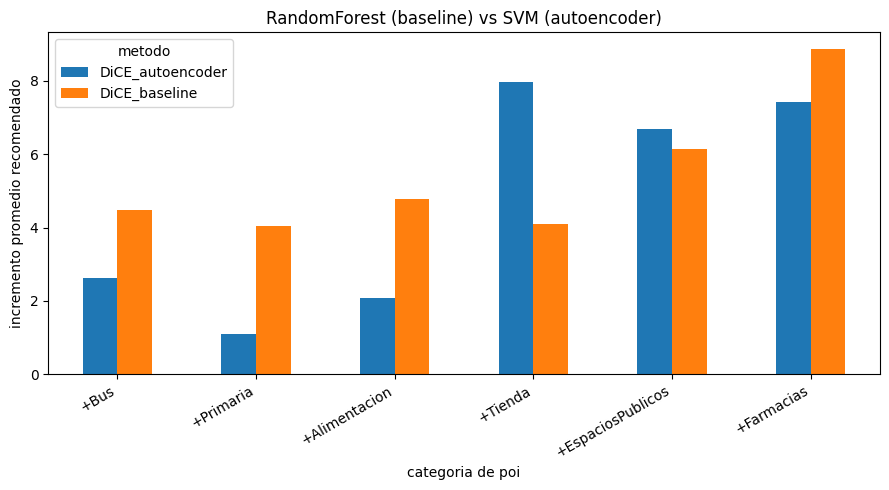

In [145]:
if per_home.empty:
    print('sin datos para graficar')
else:
    fig, ax = plt.subplots(figsize=(9,5))
    resumen.T.plot(kind='bar', ax=ax)
    ax.set_ylabel('incremento promedio recomendado')
    ax.set_xlabel('categoria de poi')
    ax.set_title(f'{mejor_baseline_nombre} (baseline) vs {mejor_ae_nombre} (autoencoder)')
    ax.legend(title='metodo')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig('comparacion_categorias_dice.png', dpi=150)
    plt.show()

## pendientes antes de reportar resultados

- calcular_scoreH usa el placeholder, reemplazar por la formula real de fase 2
- revisar si FORZAR_MODELO hace falta si el ganador automatico da validity bajo en dice
- MAX_PROYECTOS_DICE en None corre sobre todos los no habitables, puede tardar

In [148]:
cols_delta = [f'+{p}' for p in POIS_MODIFICABLES]

# si no calculaste delta_score todavia en esta celda, se calcula aca
if 'delta_score' not in per_home.columns:
    per_home['delta_score'] = per_home['score_despues'] - per_home['score_antes']

# una fila por proyecto+metodo, ordenado de mayor a menor score original
# (si un proyecto tiene varios contrafactuales, cf_num, se toma el primero -- el mejor segun DiCE)
tabla_ordenada = (per_home.sort_values(['id_proyecto','cf_num'])
                          .groupby(['id_proyecto','metodo'])
                          .first()
                          .reset_index())

tabla_ordenada = tabla_ordenada.sort_values('score_antes', ascending=False).reset_index(drop=True)

columnas_mostrar = ['id_proyecto', 'metodo', 'score_antes', 'score_despues', 'delta_score'] + cols_delta
tabla_ordenada = tabla_ordenada[columnas_mostrar]

print(f'Total de proyectos no habitables con contrafactual: {tabla_ordenada["id_proyecto"].nunique()}')
tabla_ordenada

Total de proyectos no habitables con contrafactual: 72


,id_proyecto,metodo,score_antes,score_despues,delta_score,+Bus,+Primaria,+Alimentacion,+Tienda,+EspaciosPublicos,+Farmacias
0,343,DiCE_baseline,0.5995,0.6663,0.0668,0,3,0,14,0,0
1,343,DiCE_autoencoder,0.5995,0.6327,0.0332,0,2,0,0,6,0
2,3227,DiCE_autoencoder,0.5994,0.6232,0.0238,15,0,2,0,0,0
3,3227,DiCE_baseline,0.5994,0.6714,0.0720,0,0,11,0,8,0
4,222,DiCE_baseline,0.5983,0.6308,0.0325,0,0,11,0,10,0
...,...,...,...,...,...,...,...,...,...,...,...
125,3309,DiCE_autoencoder,0.0811,0.4428,0.3617,0,0,15,13,15,14
126,13,DiCE_autoencoder,0.0722,0.2576,0.1854,0,0,0,14,12,9
127,1745,DiCE_autoencoder,0.0398,0.3181,0.2783,0,8,0,13,15,15
128,1686,DiCE_autoencoder,0.0235,0.2422,0.2187,0,0,0,14,13,15


In [149]:
print('=== DiCE_baseline, ordenado por score original ===')
display(tabla_ordenada[tabla_ordenada['metodo']=='DiCE_baseline'].reset_index(drop=True))

print('\n=== DiCE_autoencoder, ordenado por score original ===')
display(tabla_ordenada[tabla_ordenada['metodo']=='DiCE_autoencoder'].reset_index(drop=True))

=== DiCE_baseline, ordenado por score original ===


,id_proyecto,metodo,score_antes,score_despues,delta_score,+Bus,+Primaria,+Alimentacion,+Tienda,+EspaciosPublicos,+Farmacias
0,343,DiCE_baseline,0.5995,0.6663,0.0668,0,3,0,14,0,0
1,3227,DiCE_baseline,0.5994,0.6714,0.0720,0,0,11,0,8,0
2,222,DiCE_baseline,0.5983,0.6308,0.0325,0,0,11,0,10,0
3,1898,DiCE_baseline,0.5977,0.6167,0.0190,0,6,0,0,0,0
4,202,DiCE_baseline,0.5977,0.6360,0.0383,0,7,15,0,0,0
5,2315,DiCE_baseline,0.5977,0.6412,0.0435,0,0,3,0,0,5
6,174,DiCE_baseline,0.5915,0.6349,0.0434,0,0,8,0,0,11
7,1025,DiCE_baseline,0.5720,0.6698,0.0978,0,0,0,0,15,15
8,1048,DiCE_baseline,0.5642,0.6000,0.0358,0,2,0,0,0,12
9,2763,DiCE_baseline,0.5584,0.6194,0.0610,0,6,0,0,0,6



=== DiCE_autoencoder, ordenado por score original ===


,id_proyecto,metodo,score_antes,score_despues,delta_score,+Bus,+Primaria,+Alimentacion,+Tienda,+EspaciosPublicos,+Farmacias
0,343,DiCE_autoencoder,0.5995,0.6327,0.0332,0,2,0,0,6,0
1,3227,DiCE_autoencoder,0.5994,0.6232,0.0238,15,0,2,0,0,0
2,222,DiCE_autoencoder,0.5983,0.6326,0.0343,7,0,0,0,12,0
3,1898,DiCE_autoencoder,0.5977,0.6552,0.0575,13,0,0,0,0,6
4,202,DiCE_autoencoder,0.5977,0.6620,0.0643,0,0,0,12,0,10
...,...,...,...,...,...,...,...,...,...,...,...
67,3309,DiCE_autoencoder,0.0811,0.4428,0.3617,0,0,15,13,15,14
68,13,DiCE_autoencoder,0.0722,0.2576,0.1854,0,0,0,14,12,9
69,1745,DiCE_autoencoder,0.0398,0.3181,0.2783,0,8,0,13,15,15
70,1686,DiCE_autoencoder,0.0235,0.2422,0.2187,0,0,0,14,13,15


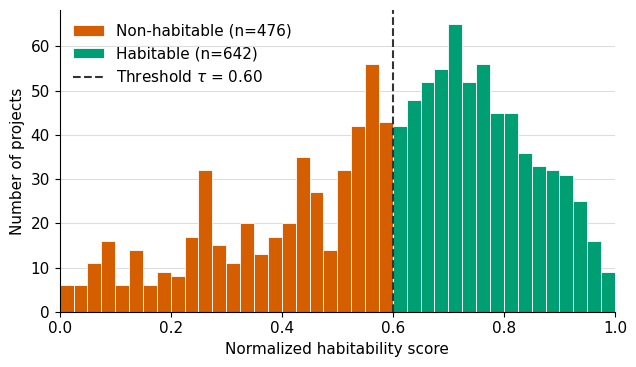

In [162]:
import numpy as np
import matplotlib.pyplot as plt

COL_HAB, COL_NOHAB = '#009E73', '#D55E00'
plt.rcParams.update({'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

bins = np.linspace(0, 1, 41)   # el umbral 0.6 cae en el borde de un bin
hab = df.loc[df['FlgHabita'] == 1, 'ScoreHNorm']
nohab = df.loc[df['FlgHabita'] == 0, 'ScoreHNorm']

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(nohab, bins=bins, color=COL_NOHAB, edgecolor='white', linewidth=0.6,
        label=f'Non-habitable (n={len(nohab)})')
ax.hist(hab, bins=bins, color=COL_HAB, edgecolor='white', linewidth=0.6,
        label=f'Habitable (n={len(hab)})')
ax.axvline(THRESHOLD, color='#333333', linestyle='--', linewidth=1.5,
           label=r'Threshold $\tau$ = 0.60')
ax.set_xlabel('Normalized habitability score')
ax.set_ylabel('Number of projects')
ax.set_xlim(0, 1)
ax.yaxis.grid(True, color='#dddddd', linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig('fig_score_distribution.pdf', bbox_inches='tight')
fig.savefig('fig_score_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

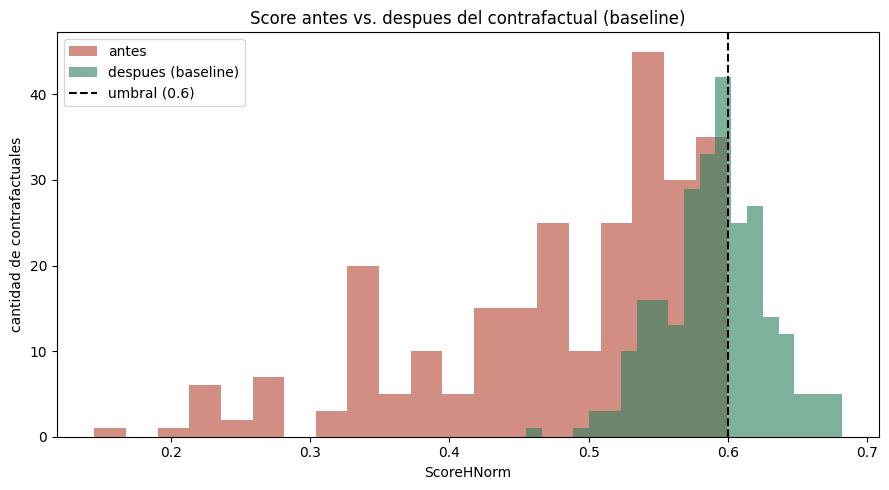

In [151]:
fig, ax = plt.subplots(figsize=(9,5))
ax.hist(per_home[per_home['metodo']=='DiCE_baseline']['score_antes'], bins=20, alpha=0.6, color='#b5432f', label='antes')
ax.hist(per_home[per_home['metodo']=='DiCE_baseline']['score_despues'], bins=20, alpha=0.6, color='#2a7f5b', label='despues (baseline)')
ax.axvline(THRESHOLD, color='black', linestyle='--', linewidth=1.5, label=f'umbral ({THRESHOLD})')
ax.set_xlabel('ScoreHNorm')
ax.set_ylabel('cantidad de contrafactuales')
ax.set_title('Score antes vs. despues del contrafactual (baseline)')
ax.legend()
plt.tight_layout()
plt.savefig('histograma_antes_despues.png', dpi=150)
plt.show()

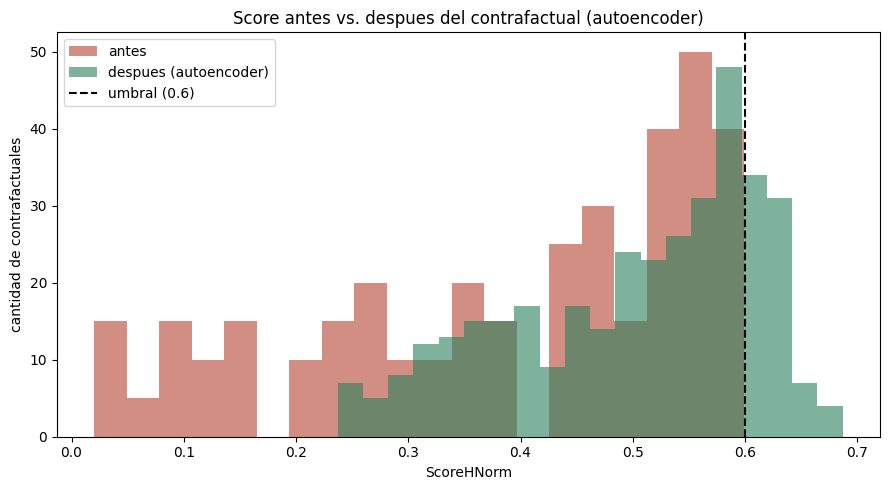

In [152]:
fig, ax = plt.subplots(figsize=(9,5))
ax.hist(per_home[per_home['metodo']=='DiCE_autoencoder']['score_antes'], bins=20, alpha=0.6, color='#b5432f', label='antes')
ax.hist(per_home[per_home['metodo']=='DiCE_autoencoder']['score_despues'], bins=20, alpha=0.6, color='#2a7f5b', label='despues (autoencoder)')
ax.axvline(THRESHOLD, color='black', linestyle='--', linewidth=1.5, label=f'umbral ({THRESHOLD})')
ax.set_xlabel('ScoreHNorm')
ax.set_ylabel('cantidad de contrafactuales')
ax.set_title('Score antes vs. despues del contrafactual (autoencoder)')
ax.legend()
plt.tight_layout()
plt.savefig('histograma_antes_despues_autoencoder.png', dpi=150)
plt.show()

In [153]:
ids_baseline = set(per_home[per_home['metodo']=='DiCE_baseline']['id_proyecto'])
ids_autoencoder = set(per_home[per_home['metodo']=='DiCE_autoencoder']['id_proyecto'])

print(f'proyectos con exito en baseline: {len(ids_baseline)}')
print(f'proyectos con exito en autoencoder: {len(ids_autoencoder)}')
print(f'en ambos: {len(ids_baseline & ids_autoencoder)}')
print(f'solo en baseline: {len(ids_baseline - ids_autoencoder)}')
print(f'solo en autoencoder: {len(ids_autoencoder - ids_baseline)}')

proyectos con exito en baseline: 58
proyectos con exito en autoencoder: 72
en ambos: 58
solo en baseline: 0
solo en autoencoder: 14


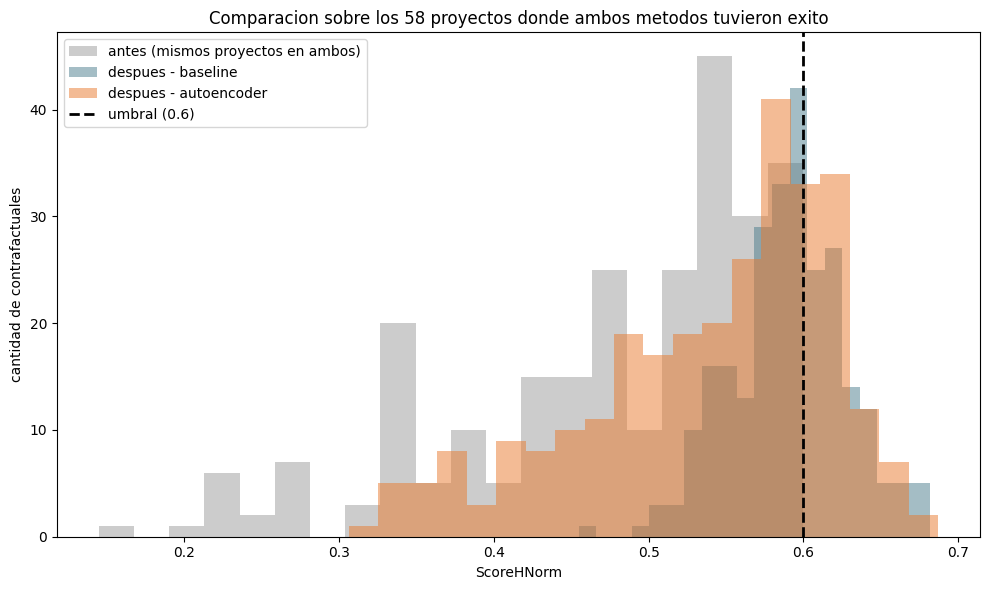

In [154]:
ids_comunes = ids_baseline & ids_autoencoder
per_home_comun = per_home[per_home['id_proyecto'].isin(ids_comunes)]

fig, ax = plt.subplots(figsize=(10,6))
ax.hist(per_home_comun[per_home_comun['metodo']=='DiCE_baseline']['score_antes'],
        bins=20, alpha=0.4, color='gray', label='antes (mismos proyectos en ambos)')
ax.hist(per_home_comun[per_home_comun['metodo']=='DiCE_baseline']['score_despues'],
        bins=20, alpha=0.5, color='#4a7c8c', label='despues - baseline')
ax.hist(per_home_comun[per_home_comun['metodo']=='DiCE_autoencoder']['score_despues'],
        bins=20, alpha=0.5, color='#e8792c', label='despues - autoencoder')
ax.axvline(THRESHOLD, color='black', linestyle='--', linewidth=2, label=f'umbral ({THRESHOLD})')
ax.set_xlabel('ScoreHNorm')
ax.set_ylabel('cantidad de contrafactuales')
ax.set_title(f'Comparacion sobre los {len(ids_comunes)} proyectos donde ambos metodos tuvieron exito')
ax.legend()
plt.tight_layout()
plt.savefig('histograma_comparacion_justa.png', dpi=150)
plt.show()

In [156]:
import pandas as pd

proyectos = pd.read_excel('proyectos_geocodificados.xlsx')

print(f'Total de proyectos en el archivo: {len(proyectos)}')
print()

conteo_precision = proyectos['precision_geocoding'].value_counts()
porcentaje_precision = proyectos['precision_geocoding'].value_counts(normalize=True) * 100

resumen = pd.DataFrame({
    'cantidad': conteo_precision,
    'porcentaje': porcentaje_precision.round(1)
})
print(resumen)

Total de proyectos en el archivo: 4389

                     cantidad  porcentaje
precision_geocoding                      
direccion                4335        98.8
distrito                   31         0.7
calle                      23         0.5


In [158]:
import pandas as pd

detalle = pd.read_csv('pois_detalle_por_proyecto.csv')

print(f'Proyectos unicos en el detalle: {detalle["id_proyecto"].nunique()}')
print()

conteo_por_proyecto = (detalle.groupby(['id_proyecto', 'categoria'])
                              .size()
                              .unstack('categoria', fill_value=0))

POI_COLS = ['Bus', 'Primaria', 'Universitaria', 'Hospitales',
            'Alimentacion', 'Tienda', 'EspaciosPublicos', 'Farmacias']
for c in POI_COLS:
    if c not in conteo_por_proyecto.columns:
        conteo_por_proyecto[c] = 0
conteo_por_proyecto = conteo_por_proyecto[POI_COLS]

tabla = pd.DataFrame({
    'Total': conteo_por_proyecto.sum(),
    'Avg': conteo_por_proyecto.mean().round(2),
    'Min': conteo_por_proyecto.min(),
    'Max': conteo_por_proyecto.max(),
})

print(tabla)

Proyectos unicos en el detalle: 1118

                  Total    Avg  Min  Max
categoria                               
Bus                7909   7.07    0   59
Primaria          22122  19.79    0   66
Universitaria      3338   2.99    0   28
Hospitales         5327   4.76    0   23
Alimentacion      37439  33.49    0  333
Tienda             8064   7.21    0   47
EspaciosPublicos   9339   8.35    0   37
Farmacias         11468  10.26    0   46


In [159]:
import pandas as pd

df = pd.read_csv('dataset_fase3_final.csv')

for col in ['Pobreza monetaria 2018', 'DENUNCIAS_2017']:
    print(col)
    print(f"  min:  {df[col].min():.2f}")
    print(f"  max:  {df[col].max():.2f}")
    print(f"  mean: {df[col].mean():.2f}")
    print(f"  std:  {df[col].std():.2f}")
    print()

Pobreza monetaria 2018
  min:  0.10
  max:  26.10
  mean: 8.83
  std:  6.58

DENUNCIAS_2017
  min:  152.00
  max:  13948.00
  mean: 5194.38
  std:  3938.83



In [160]:
ids_nh = set(proyectos_no_habitables['id_proyecto'])
for m in ['DiCE_baseline', 'DiCE_autoencoder']:
    sub = per_home[per_home['metodo'] == m]
    print(m, '| proyectos con al menos un CF:', sub['id_proyecto'].nunique(), 'de', len(ids_nh),
          '| CFs:', len(sub),
          '| score_despues >= umbral:', round((sub['score_despues'] >= THRESHOLD).mean(), 3))

mejor = (per_home.sort_values('costo_total')
                 .groupby(['id_proyecto', 'metodo']).first().reset_index())
piv = mejor.pivot(index='id_proyecto', columns='metodo', values='costo_total').dropna()

from scipy.stats import wilcoxon
print('proyectos con CF en ambos:', len(piv))
print(piv.median())
print(wilcoxon(piv['DiCE_autoencoder'], piv['DiCE_baseline']))

DiCE_baseline | proyectos con al menos un CF: 58 de 72 | CFs: 260 | score_despues >= umbral: 0.373
DiCE_autoencoder | proyectos con al menos un CF: 72 de 72 | CFs: 360 | score_despues >= umbral: 0.2
proyectos con CF en ambos: 58
metodo
DiCE_autoencoder    580.0
DiCE_baseline       855.0
dtype: float64
WilcoxonResult(statistic=np.float64(91.0), pvalue=np.float64(5.096899569159335e-09))


In [161]:
ids_b = set(per_home[per_home['metodo']=='DiCE_baseline']['id_proyecto'])
ids_a = set(per_home[per_home['metodo']=='DiCE_autoencoder']['id_proyecto'])
comunes = ids_b & ids_a
pc = per_home[per_home['id_proyecto'].isin(comunes)].copy()
pc['cumple_score'] = pc['score_despues'] >= THRESHOLD

print(pc.groupby('metodo').agg(
    n_cfs=('cf_num','size'), validity=('valido','mean'),
    score_consistente=('cumple_score','mean'), sparsity=('sparsity','mean'),
    L1=('proximity_L1','mean'), L2=('proximity_L2','mean'),
    delta=('delta_score','mean'), costo=('costo_total','mean')).round(3))

# exito por proyecto segun la regla real: al menos un CF con score >= umbral
print(pc.groupby(['metodo','id_proyecto'])['cumple_score'].any().groupby('metodo').mean())

# costo del CF mas barato que si cumple el score
ok = pc[pc['cumple_score']]
print(ok.sort_values('costo_total').groupby(['metodo','id_proyecto']).first()
        .reset_index().groupby('metodo')['costo_total'].describe())

# hipotesis de seleccion: score inicial de los 14 proyectos que solo cubre el autoencoder
print(per_home[per_home['id_proyecto'].isin(ids_a - ids_b)].drop_duplicates('id_proyecto')['score_antes'].describe())
print(pc.drop_duplicates('id_proyecto')['score_antes'].describe())

                  n_cfs  validity  score_consistente  sparsity      L1  \
metodo                                                                   
DiCE_autoencoder    290     1.000              0.248     2.193  23.955   
DiCE_baseline       260     0.908              0.373     2.854  32.400   

                      L2  delta     costo  
metodo                                     
DiCE_autoencoder  16.593  0.085  1289.448  
DiCE_baseline     19.242  0.111  2040.192  
metodo
DiCE_autoencoder    0.37931
DiCE_baseline       0.50000
Name: cumple_score, dtype: float64
                  count         mean          std    min    25%    50%  \
metodo                                                                   
DiCE_autoencoder   22.0   603.181818   414.112779   80.0  310.0  580.0   
DiCE_baseline      29.0  1156.551724  1134.291081  180.0  470.0  740.0   

                     75%     max  
metodo                            
DiCE_autoencoder   692.5  1800.0  
DiCE_baseline     1320.0  4

In [163]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

COL_BASE, COL_AE, COL_ANTES = '#0072B2', '#CC79A7', '#4D4D4D'
plt.rcParams.update({'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

# base comun: los 58 proyectos con contrafactual en ambas ramas
ids_b = set(per_home.loc[per_home['metodo'] == 'DiCE_baseline', 'id_proyecto'])
ids_a = set(per_home.loc[per_home['metodo'] == 'DiCE_autoencoder', 'id_proyecto'])
comunes = sorted(ids_a & ids_b)
pc = per_home[per_home['id_proyecto'].isin(comunes)]
cols_delta = [f'+{p}' for p in POIS_MODIFICABLES]
mejor = (pc.sort_values('costo_total')
           .groupby(['id_proyecto', 'metodo']).first().reset_index())

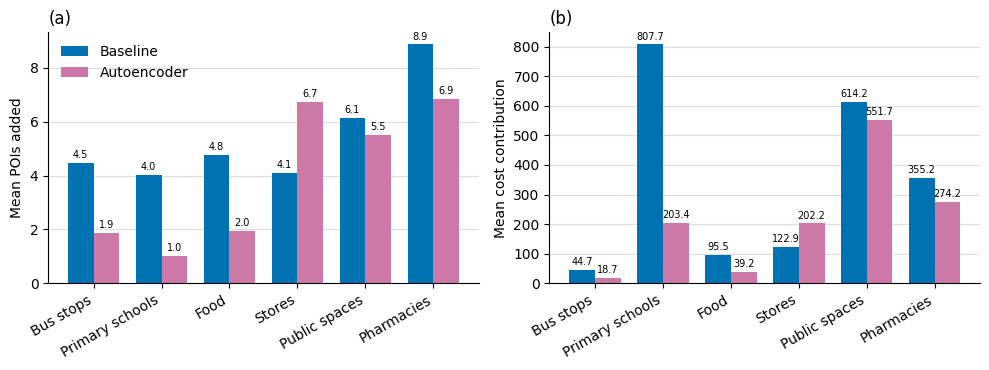

In [164]:
# Figura 1: POIs agregados y contribucion al costo, por subcategoria
etiquetas = ['Bus stops', 'Primary schools', 'Food', 'Stores', 'Public spaces', 'Pharmacies']
costo_unit = np.array([cost_dict[p] for p in POIS_MODIFICABLES])   # debe coincidir con la tabla de costos
medias = pc.groupby('metodo')[cols_delta].mean()
x, w = np.arange(len(etiquetas)), 0.38

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, datos, ylab, tag in [(axes[0], medias, 'Mean POIs added', '(a)'),
                             (axes[1], medias * costo_unit, 'Mean cost contribution', '(b)')]:
    b1 = ax.bar(x - w/2, datos.loc['DiCE_baseline'], w, color=COL_BASE, label='Baseline')
    b2 = ax.bar(x + w/2, datos.loc['DiCE_autoencoder'], w, color=COL_AE, label='Autoencoder')
    ax.bar_label(b1, fmt='%.1f', fontsize=7, padding=2)
    ax.bar_label(b2, fmt='%.1f', fontsize=7, padding=2)
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas, rotation=30, ha='right')
    ax.set_ylabel(ylab)
    ax.set_title(tag, loc='left')
    ax.yaxis.grid(True, color='#dddddd', linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig('fig_cf_composition.pdf', bbox_inches='tight')
fig.savefig('fig_cf_composition.png', dpi=300, bbox_inches='tight')
plt.show()

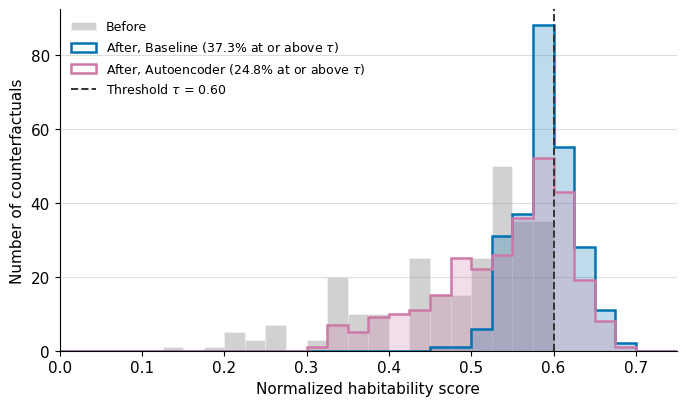

In [168]:
import numpy as np
import matplotlib.pyplot as plt

COL_BASE, COL_AE, COL_ANTES = '#0072B2', '#CC79A7', '#9A9A9A'
plt.rcParams.update({'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

ids_comunes = ids_baseline & ids_autoencoder
pc = per_home[per_home['id_proyecto'].isin(ids_comunes)]
base = pc[pc['metodo'] == 'DiCE_baseline']
ae = pc[pc['metodo'] == 'DiCE_autoencoder']

bins = np.linspace(0, 0.8, 33)   # ancho 0.025, el umbral 0.6 cae en un borde

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(base['score_antes'], bins=bins, color=COL_ANTES, alpha=0.45,
        edgecolor='white', linewidth=0.5, label='Before')

for datos, color, nombre in [(base, COL_BASE, 'Baseline'), (ae, COL_AE, 'Autoencoder')]:
    pct = 100 * (datos['score_despues'] >= THRESHOLD).mean()
    ax.hist(datos['score_despues'], bins=bins, histtype='stepfilled',
            color=color, alpha=0.25, linewidth=0)
    ax.hist(datos['score_despues'], bins=bins, histtype='step',
            color=color, linewidth=1.8,
            label=fr'After, {nombre} ({pct:.1f}% at or above $\tau$)')

ax.axvline(THRESHOLD, color='#333333', linestyle='--', linewidth=1.4,
           label=r'Threshold $\tau$ = 0.60')
ax.set_xlabel('Normalized habitability score')
ax.set_ylabel('Number of counterfactuals')
ax.set_xlim(0, 0.75)
ax.yaxis.grid(True, color='#dddddd', linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left', fontsize=9)
fig.tight_layout()
fig.savefig('fig_score_before_after.pdf', bbox_inches='tight')
fig.savefig('fig_score_before_after.png', dpi=300, bbox_inches='tight')
plt.show()

In [170]:
from google.colab import files
files.download('fig_score_before_after.pdf')
files.download('fig_score_before_after.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
tonos = ['#9AABBB', '#8699AB', '#73879B', '#61758B', '#4F6379', '#3E5268']
color = dict(zip(cats, tonos))

Filas para la tabla de LaTeX:
Bus stops        & 377 & 120 \\
Primary schools  & 189 & 150 \\
Stores           & 345 & 100 \\
Food             & 219 & 80 \\
Pharmacies       & 351 & 100 \\
Public spaces    & 301 & 150 \\

Proyectos con al menos un POI por categoria:
categoria
Bus                 1100
Primaria            1382
Tienda              1192
Alimentacion        1286
Farmacias           1206
EspaciosPublicos    1269
Name: id_proyecto, dtype: int64


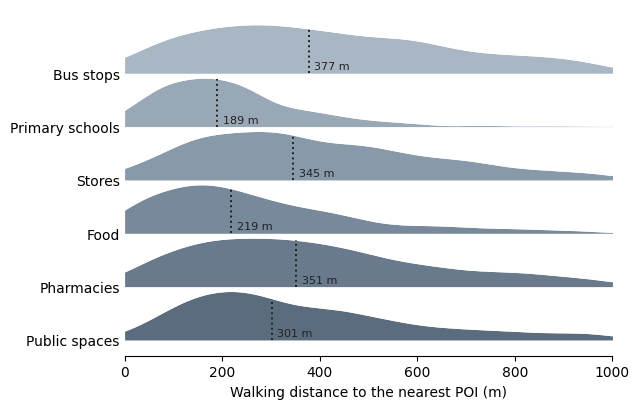

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

detalle = pd.read_csv('pois_detalle_por_proyecto.csv')

cats = ['Bus', 'Primaria', 'Tienda', 'Alimentacion', 'Farmacias', 'EspaciosPublicos']
etiqueta = {'Bus': 'Bus stops', 'Primaria': 'Primary schools', 'Tienda': 'Stores',
            'Alimentacion': 'Food', 'Farmacias': 'Pharmacies', 'EspaciosPublicos': 'Public spaces'}
#color = {'Bus': '#0072B2', 'Primaria': '#6A3D9A', 'Tienda': '#D55E00',
 #        'Alimentacion': '#C2185B', 'Farmacias': '#00897B', 'EspaciosPublicos': '#558B2F'}
separacion = {'Bus': 120, 'Primaria': 150, 'Tienda': 100, 'Alimentacion': 80, 'Farmacias': 100, 'EspaciosPublicos': 150}

# distancia caminando al POI mas cercano de cada categoria, por proyecto
minimas = (detalle[detalle['categoria'].isin(cats)]
           .groupby(['id_proyecto', 'categoria'])['dist_caminando_m'].min().reset_index())
mu = minimas.groupby('categoria')['dist_caminando_m'].median().reindex(cats)

print('Filas para la tabla de LaTeX:')
for c in cats:
    print(f'{etiqueta[c]:<16} & {mu[c]:.0f} & {separacion[c]} \\\\')
print('\nProyectos con al menos un POI por categoria:')
print(minimas.groupby('categoria')['id_proyecto'].nunique().reindex(cats))

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False})
xs = np.linspace(0, 1000, 500)
paso = 1.1
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for i, c in enumerate(reversed(cats)):
    d = minimas.loc[minimas['categoria'] == c, 'dist_caminando_m'].values
    dens = gaussian_kde(d, bw_method=0.25)
    y = dens(xs); ymax = y.max(); y = y / ymax
    base = i * paso
    ax.fill_between(xs, base, base + y, color=color[c], alpha=0.85, linewidth=0)
    ax.plot(xs, base + y, color='white', linewidth=0.8)
    ax.plot([mu[c], mu[c]], [base, base + dens(mu[c])[0] / ymax], color='#222222', linestyle=':', linewidth=1.4)
    ax.text(mu[c] + 12, base + 0.04, f'{mu[c]:.0f} m', fontsize=8, va='bottom', color='#222222')
ax.set_yticks([i * paso for i in range(len(cats))])
ax.set_yticklabels([etiqueta[c] for c in reversed(cats)])
ax.tick_params(axis='y', length=0)
ax.set_xlim(0, 1000)
ax.set_xlabel('Walking distance to the nearest POI (m)')
fig.tight_layout()
fig.savefig('fig_distance_distributions.pdf', bbox_inches='tight')
fig.savefig('fig_distance_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

In [4]:
from google.colab import files
files.download('fig_distance_distributions.pdf')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>